# Part A: Dataset overview

Before any analysis, we look at what the dataset contains: which folders and files exist, what one file looks like, which columns it has, and how many recordings and variables there are.

The dataset (causRCA) comes from a CNC lathe (a machine tool). It has three parts:
- **real_op**: recordings of the real machine in normal operation (no faults)
- **dig_twin**: recordings from a simulation of the machine ("digital twin") in which faults were injected on purpose
- **expert_graph**: a diagram made by engineers that shows which machine signal influences which other signal

In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# the notebook runs from the notebooks/ folder, so the data is one level up
RAW = Path('../data/raw/causRCA')

# top-level folders and files
for item in sorted(RAW.iterdir()):
    print(item.name)

README_DATASET.md
dig_twin
expert_graph
real_op


In [5]:
# count files per top-level folder and file type
rows = []
for folder in ['real_op', 'dig_twin', 'expert_graph']:
    for f in (RAW / folder).rglob('*'):
        if f.is_file():
            rows.append({'folder': folder, 'file_type': f.suffix})

file_counts = pd.DataFrame(rows).value_counts().unstack(fill_value=0)
file_counts

file_type,.csv,.gml,.html,.json
folder,,,,
dig_twin,106,3,3,119
expert_graph,2,1,1,0
real_op,170,0,0,0


In [6]:
# list the normal-operation files
real_files = sorted((RAW / 'real_op').glob('*.csv'))
print('number of normal-operation files:', len(real_files))
print('first file:', real_files[0].name)

# read the first file
df = pd.read_csv(real_files[0])
print('shape (rows, columns):', df.shape)
df.head(10)

number of normal-operation files: 170
first file: dataset_real_op_28610.csv
shape (rows, columns): (3326, 4)


,time_s,node,value,type
0,0.0,CBC_Closed,True,Binary
1,0.0,CBC_close,True,Binary
2,0.0,CBC_isOpen,False,Binary
3,0.0,CBC_open,False,Binary
4,0.0,CLF_Filter_Ok,True,Binary
5,0.0,CLT_Level_lt_Min,False,Binary
6,0.0,ExU_On,True,Binary
7,0.0,ExU_isOff,False,Binary
8,0.0,F_Filter_Ok,True,Binary
9,0.0,HP_Pump_Ok,True,Binary


Each file is an **event log**. A new row is written only when a signal changes its value. The four columns are:

| column | meaning |
|---|---|
| `time_s` | seconds since the recording started |
| `node` | the name of the machine signal (variable), e.g. `HP_Pump_Ok` |
| `value` | the new value of that signal |
| `type` | the kind of signal: Binary (true/false), Alarm, Continuous (a measurement), Counter, Categorical (a name or code) |

In [7]:
# column names and data types
print(df.dtypes, '\n')

# how many different variables (signals) are in this one file
print('different variables in this file:', df['node'].nunique())

# how many rows each signal type has
df['type'].value_counts()

time_s    float64
node       object
value      object
type       object
dtype: object 

different variables in this file: 74


type
Continuous     1270
Counter         777
Categorical     686
Binary          566
Alarm            27
Name: count, dtype: int64

In [8]:
# a few example values for each type, to see what the data looks like
for t, group in df.groupby('type'):
    print(f'{t:12s} examples:', group['value'].unique()[:6])

Alarm        examples: ['False' 'True']
Binary       examples: ['True' 'False']
Categorical  examples: ['322' 'MEAS_X_SPF' 'MEAS_X_SPF|322' '3D_PROBE' '341' 'MEAS_X_SPF|341']
Continuous   examples: ['30.0' '155.006' '384.666' '0.0' '100.0' '148.499']
Counter      examples: ['46073.0' '7830237.617' '11762.224' '11763.224' '7830238.557' '11764.224']


In [9]:
# one row per file: number of rows, duration and number of variables
summary = []
for f in real_files:
    d = pd.read_csv(f)
    summary.append({
        'file': f.name,
        'rows': len(d),
        'duration_s': d['time_s'].max(),
        'variables': d['node'].nunique(),
    })
real_summary = pd.DataFrame(summary)

print('total rows in all normal files:', real_summary['rows'].sum())
real_summary.describe().round(1)

total rows in all normal files: 402666


,rows,duration_s,variables
count,170.0,170.0,170.0
mean,2368.6,581.9,74.1
std,1541.2,51.0,0.6
min,78.0,80.1,73.0
25%,551.2,590.6,74.0
50%,3311.0,599.5,74.0
75%,3626.2,599.9,74.0
max,4426.0,613.7,78.0


In [21]:
# duration of every fault run, in minutes
fault_files = sorted((RAW / 'dig_twin').rglob('run_*/*.csv'))
fault_minutes = pd.Series([pd.read_csv(f, usecols=['time_s'])['time_s'].max() / 60 for f in fault_files])
fault_minutes.describe().round(2)

count    100.00
mean       3.70
std        0.81
min        2.34
25%        3.17
50%        3.65
75%        4.13
max        6.07
dtype: float64

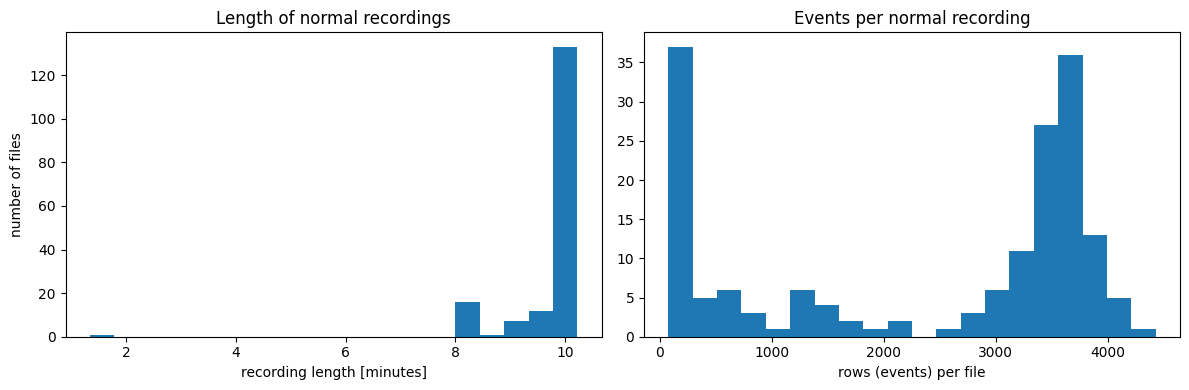

In [12]:
# how long the recordings are and how many rows they have
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(real_summary['duration_s'] / 60, bins=20)
ax1.set_xlabel('recording length [minutes]')
ax1.set_ylabel('number of files')
ax1.set_title('Length of normal recordings')
ax2.hist(real_summary['rows'], bins=20)
ax2.set_xlabel('rows (events) per file')
ax2.set_title('Events per normal recording')
plt.tight_layout()
plt.show()

In [13]:
# dig_twin -> subsystem -> experiment -> run
rows = []
for subsystem_dir in sorted((RAW / 'dig_twin').iterdir()):
    if not subsystem_dir.is_dir():
        continue
    for exp_dir in sorted(subsystem_dir.iterdir()):
        if exp_dir.is_dir():
            runs = [r for r in exp_dir.iterdir() if r.is_dir()]
            rows.append({'subsystem': subsystem_dir.name, 'experiment': exp_dir.name, 'runs': len(runs)})
fault_overview = pd.DataFrame(rows)

print('number of fault experiments:', len(fault_overview))
print('number of fault runs:', fault_overview['runs'].sum())
fault_overview

number of fault experiments: 19
number of fault runs: 100


,subsystem,experiment,runs
0,exp_coolant,exp_22,6
1,exp_coolant,exp_27,7
2,exp_coolant,exp_28,6
3,exp_coolant,exp_35,6
4,exp_hydraulics,exp_10,5
5,exp_hydraulics,exp_12,5
6,exp_hydraulics,exp_13,4
7,exp_hydraulics,exp_14,4
8,exp_hydraulics,exp_15,5
9,exp_hydraulics,exp_18,5


In [15]:
# one example run folder
run_dir = RAW / 'dig_twin' / 'exp_coolant' / 'exp_22' / 'run_1'
for f in sorted(run_dir.iterdir()):
    print(f.name)

# the run's csv has the same 4 columns as the normal files
fault_df = pd.read_csv(next(run_dir.glob('*.csv')))
print('\nshape:', fault_df.shape)
fault_df.head()

causes.json
faultDataset_coolant_exp22_run_1.csv

shape: (1214, 4)


,time_s,node,value,type
0,0.0,CBC_Closed,True,Binary
1,0.0,CBC_close,True,Binary
2,0.0,CBC_isOpen,False,Binary
3,0.0,CBC_open,False,Binary
4,0.0,ExU_On,False,Binary


In [16]:
import json

# causes.json: only times (in seconds) of the fault, no variable names
print(json.dumps(json.load(open(run_dir / 'causes.json')), indent=2))

# the experiment description: which variables were broken on purpose (the true causes)
description = json.load(open(run_dir.parent / 'exp_22_description.json'))
print('\nkeys:', list(description))
print('manipulated variables (true causes):', description['manipulatedVars'])
print('alarms that should appear:', description['alarms'])

{
  "cause_start_at": 106.927,
  "alarms_detected_at": 155.546,
  "diagnosis_at": 180.476,
  "cause_end_at": 205.406,
  "alarms_resolved_at": 262.931
}

keys: ['exp_id', 'group', 'scenario', 'manipulatedVars', 'alarms', 'diagnoses']
manipulated variables (true causes): ['HP_Pump_Ok', 'LT_Level_Ok']
alarms that should appear: ['HP_A_700304', 'LT_A_700317']


**The expert graph** is a list of signals (nodes) and arrows between them (edges). An arrow `A → B` means an engineer says A influences B. For example, `HP_Pump_Ok → HP_A_700304` means a failed pump triggers that alarm.

The same graph is stored three times:
- as two tables, `all_nodes.csv` and `all_edges.csv`
- as `expert_graph.gml`, a standard text format for graphs (GML = Graph Modelling Language) that graph libraries can read directly
- as `expert_graph.html`, an interactive picture for the browser

We only need the tables to understand it.

In [20]:
nodes = pd.read_csv(RAW / 'expert_graph' / 'all_nodes.csv')
edges = pd.read_csv(RAW / 'expert_graph' / 'all_edges.csv')
print('nodes (signals):', len(nodes), '| edges (arrows):', len(edges))
print('\nnode columns:', list(nodes.columns))
print('edge columns:', list(edges.columns))
edges[['source_label', 'target_label', 'comment']].head(8)

nodes (signals): 92 | edges (arrows): 104

node columns: ['id', 'path', 'label', 'type', 'io', 'datatype', 'examples', 'comment']
edge columns: ['source_id', 'target_id', 'source_label', 'target_label', 'edge_name', 'comment']


,source_label,target_label,comment
0,CLF_A_700307,M_WarnWithStacklight,Clogged coolant filter triggers a warning with...
1,CLF_Filter_Ok,CLF_A_700307,When Filter_OK=False for at least 5 seconds ->...
2,F_Filter_Ok,F_A_700313,When Fleece_Filter_Ok=False for at least 5 sec...
3,HP_A_700304,M_ErrorActive,High pressure pump motor protection alarm trig...
4,HP_Pump_Ok,HP_A_700304,When HP_Pump_Ok=False -> Alarm 700304 is trigg...
5,HP_Pump_Ok,HP_Pump_isOff,"When HP_Pump_Ok=False, then HP_Pump_isOff=True..."
6,LT_Level_Ok,LT_A_700317,When LT_Level_Ok=False -> Alarm 700317 is trig...
7,LT_Level_Ok,LT_Pump_Ok,"When LT_Level_Ok=False -> LT_Pump_Ok=False, i...."


In [18]:
# collect every (variable, type) pair from all normal files and all fault runs
fault_files = sorted((RAW / 'dig_twin').rglob('run_*/*.csv'))
pairs = set()
for f in real_files + fault_files:
    d = pd.read_csv(f, usecols=['node', 'type'])
    pairs.update(zip(d['node'], d['type']))
variables = pd.DataFrame(sorted(pairs), columns=['variable', 'type'])

print('total files read:', len(real_files) + len(fault_files))
print('distinct variables in the dataset:', variables['variable'].nunique())
variables['type'].value_counts()

total files read: 270
distinct variables in the dataset: 96


type
Binary         64
Alarm          18
Continuous      7
Categorical     4
Counter         3
Name: count, dtype: int64

In [19]:
# missing values, duplicate rows and time order, over all files
problems = []
for f in real_files + fault_files:
    d = pd.read_csv(f)
    problems.append({
        'file': f.name,
        'missing_values': int(d.isna().sum().sum()),
        'duplicate_rows': int(d.duplicated().sum()),
        'time_sorted': d['time_s'].is_monotonic_increasing,
    })
problems = pd.DataFrame(problems)

print('files with missing values:', (problems['missing_values'] > 0).sum())
print('files with duplicate rows:', (problems['duplicate_rows'] > 0).sum())
print('files not sorted by time:', (~problems['time_sorted']).sum())

files with missing values: 0
files with duplicate rows: 0
files not sorted by time: 0


**Summary of the dataset**
- normal-operation files: 170 ; fault runs: 100 in 19 experiments (3 subsystems: coolant, hydraulics, probe)
- every file is an event log with 4 columns: `time_s`, `node`, `value`, `type`
- distinct variables: _96__ (mostly Binary signals and Alarms)
- normal recordings last about 10 minutes, fault runs about 3.7 minutes
- data quality: 0 files with missing values, _0 with duplicates, 0 unsorted
- the true cause of each fault is in the experiment's description file (`manipulatedVars`), not in `causes.json`